In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [13]:
df = pd.read_csv("JEE_Dropout_After_Class_12.csv")

In [14]:
df.head()

,jee_main_score,jee_advanced_score,mock_test_score_avg,school_board,class_12_percent,attempt_count,coaching_institute,daily_study_hours,family_income,parent_education,location_type,peer_pressure_level,mental_health_issues,admission_taken,dropout
0,78.95,59.22,59.86,CBSE,70.09,1,FIITJEE,5.4,Low,Upto 10th,Urban,Low,No,No,1
1,70.06,58.75,64.33,State,78.00,1,FIITJEE,5.5,Mid,Upto 10th,Urban,Low,Yes,No,0
2,81.07,37.27,60.83,ICSE,64.36,1,FIITJEE,7.0,Low,PG,Semi-Urban,Medium,Yes,No,1
3,93.32,60.72,69.33,ICSE,73.21,1,FIITJEE,2.1,Low,12th,Semi-Urban,Medium,Yes,Yes,0
4,68.72,77.73,82.37,CBSE,89.02,1,Allen,6.3,Mid,Graduate,Semi-Urban,High,No,Yes,0


In [15]:
df = pd.get_dummies(df, drop_first=True)

In [16]:
X = df.drop("dropout", axis=1).values
y = df["dropout"].values

In [21]:
X = X.astype(float)
X = (X - X.mean(axis=0)) / X.std(axis=0)

In [23]:
split = int(0.8 * len(X))

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

In [24]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Initialize Parameters
weights = np.zeros(X_train.shape[1])
bias = 0

learning_rate = 0.01
epochs = 1000

In [25]:
for i in range(epochs):

    z = np.dot(X_train, weights) + bias
    y_pred = sigmoid(z)

    dw = np.dot(X_train.T, (y_pred - y_train)) / len(X_train)
    db = np.sum(y_pred - y_train) / len(X_train)

    weights = weights - learning_rate * dw
    bias = bias - learning_rate * db

In [26]:
z = np.dot(X_test, weights) + bias
probabilities = sigmoid(z)

predictions = (probabilities >= 0.5).astype(int)

In [32]:
TP = np.sum((y_test == 1) & (predictions == 1))
TN = np.sum((y_test == 0) & (predictions == 0))
FP = np.sum((y_test == 0) & (predictions == 1))
FN = np.sum((y_test == 1) & (predictions == 0))

print("Confusion Matrix")
print([[TN, FP],
       [FN, TP]])

Confusion Matrix
[[np.int64(786), np.int64(0)], [np.int64(36), np.int64(178)]]


In [33]:
# Metrics
accuracy = (TP + TN) / (TP + TN + FP + FN)

precision = TP / (TP + FP)

recall = TP / (TP + FN)

f1_score = (2 * precision * recall) / (precision + recall)

print("\nAccuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1_score)


Accuracy : 0.964
Precision: 1.0
Recall   : 0.8317757009345794
F1 Score : 0.9081632653061225


In [41]:
# ROC Curve
thresholds = np.arange(0, 1.01, 0.1)

TPR = []
FPR = []

for t in thresholds:

    pred = (probabilities >= t).astype(int)

    TP = np.sum((y_test == 1) & (pred == 1))
    TN = np.sum((y_test == 0) & (pred == 0))
    FP = np.sum((y_test == 0) & (pred == 1))
    FN = np.sum((y_test == 1) & (pred == 0))

    tpr = TP / (TP + FN) if (TP + FN) > 0 else 0
    fpr = FP / (FP + TN) if (FP + TN) > 0 else 0

    TPR.append(tpr)
    FPR.append(fpr)

AUC Score: -0.9348707521818744


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13588\3230327268.py:2: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  auc = np.trapz(TPR, FPR)


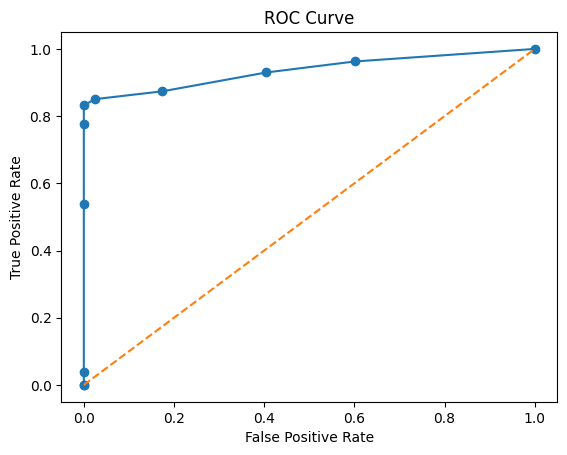

In [42]:
# AUC
auc = np.trapz(TPR, FPR)

print("AUC Score:", auc)

# Plot ROC Curve
plt.plot(FPR, TPR, marker='o')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()